# mRNA-VIP — Exploratory Data Analysis

## Project Overview
This notebook performs exploratory data analysis on the cleaned
mRNA-VIP project dataset.

### Objectives
- Understand dataset structure and feature distributions.
- Validate data quality.
- Explore numerical and categorical variables.
- Examine relationships between features.
- Visualize reaction-score patterns.

### Dataset
`../data/patient_records_clean.csv`

**Disclaimer:** Student engineering project output only. Not real clinical, medical, or regulatory guidance.

In [17]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 120

print("Libraries imported successfully.")

Libraries imported successfully.


In [18]:
# Resolve dataset path relative to this notebook

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "patient_records_clean.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (500, 7)


,Patient_ID,Age,Biomarker_Level,Pre_Existing_Conditions,Vaccine_Dose_mcg,Prior_Reaction_History,Reaction_Score
0,P0001,24,4.53,1,83.5,Mild,1
1,P0002,70,1.65,1,46.2,Mild,0
2,P0003,62,1.92,1,124.6,Mild,1
3,P0004,47,12.48,1,57.6,Mild,1
4,P0005,47,2.11,1,44.2,Mild,0


In [19]:
print("Dataset Information")
print("-" * 50)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset Information
--------------------------------------------------
Rows: 500
Columns: 7

Column names:
['Patient_ID', 'Age', 'Biomarker_Level', 'Pre_Existing_Conditions', 'Vaccine_Dose_mcg', 'Prior_Reaction_History', 'Reaction_Score']

Data types:


,Data Type
Patient_ID,str
Age,int64
Biomarker_Level,float64
Pre_Existing_Conditions,int64
Vaccine_Dose_mcg,float64
Prior_Reaction_History,str
Reaction_Score,int64



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Patient_ID,500,500,P0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,500.0,NaN,NaN,NaN,51.444,19.444976,18.0,35.0,51.0,68.25,85.0
Biomarker_Level,500.0,NaN,NaN,NaN,5.2649,2.785433,0.64,3.2675,4.82,6.8425,15.76
Pre_Existing_Conditions,500.0,NaN,NaN,NaN,1.262,1.195078,0.0,0.0,1.0,2.0,4.0
Vaccine_Dose_mcg,500.0,NaN,NaN,NaN,86.5524,36.232862,25.1,56.775,84.55,118.675,150.0
Prior_Reaction_History,500,2,Mild,458,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reaction_Score,500.0,NaN,NaN,NaN,0.49,0.500401,0.0,0.0,0.0,1.0,1.0


In [20]:
print("Missing Values")
display(df.isnull().sum().to_frame(name="Missing Count"))

print("\nDuplicate Records:", df.duplicated().sum())

print("\nUnique Values per Column:")
display(df.nunique().to_frame(name="Unique Values"))

Missing Values


,Missing Count
Patient_ID,0
Age,0
Biomarker_Level,0
Pre_Existing_Conditions,0
Vaccine_Dose_mcg,0
Prior_Reaction_History,0
Reaction_Score,0



Duplicate Records: 0

Unique Values per Column:


,Unique Values
Patient_ID,500
Age,68
Biomarker_Level,388
Pre_Existing_Conditions,5
Vaccine_Dose_mcg,417
Prior_Reaction_History,2
Reaction_Score,2


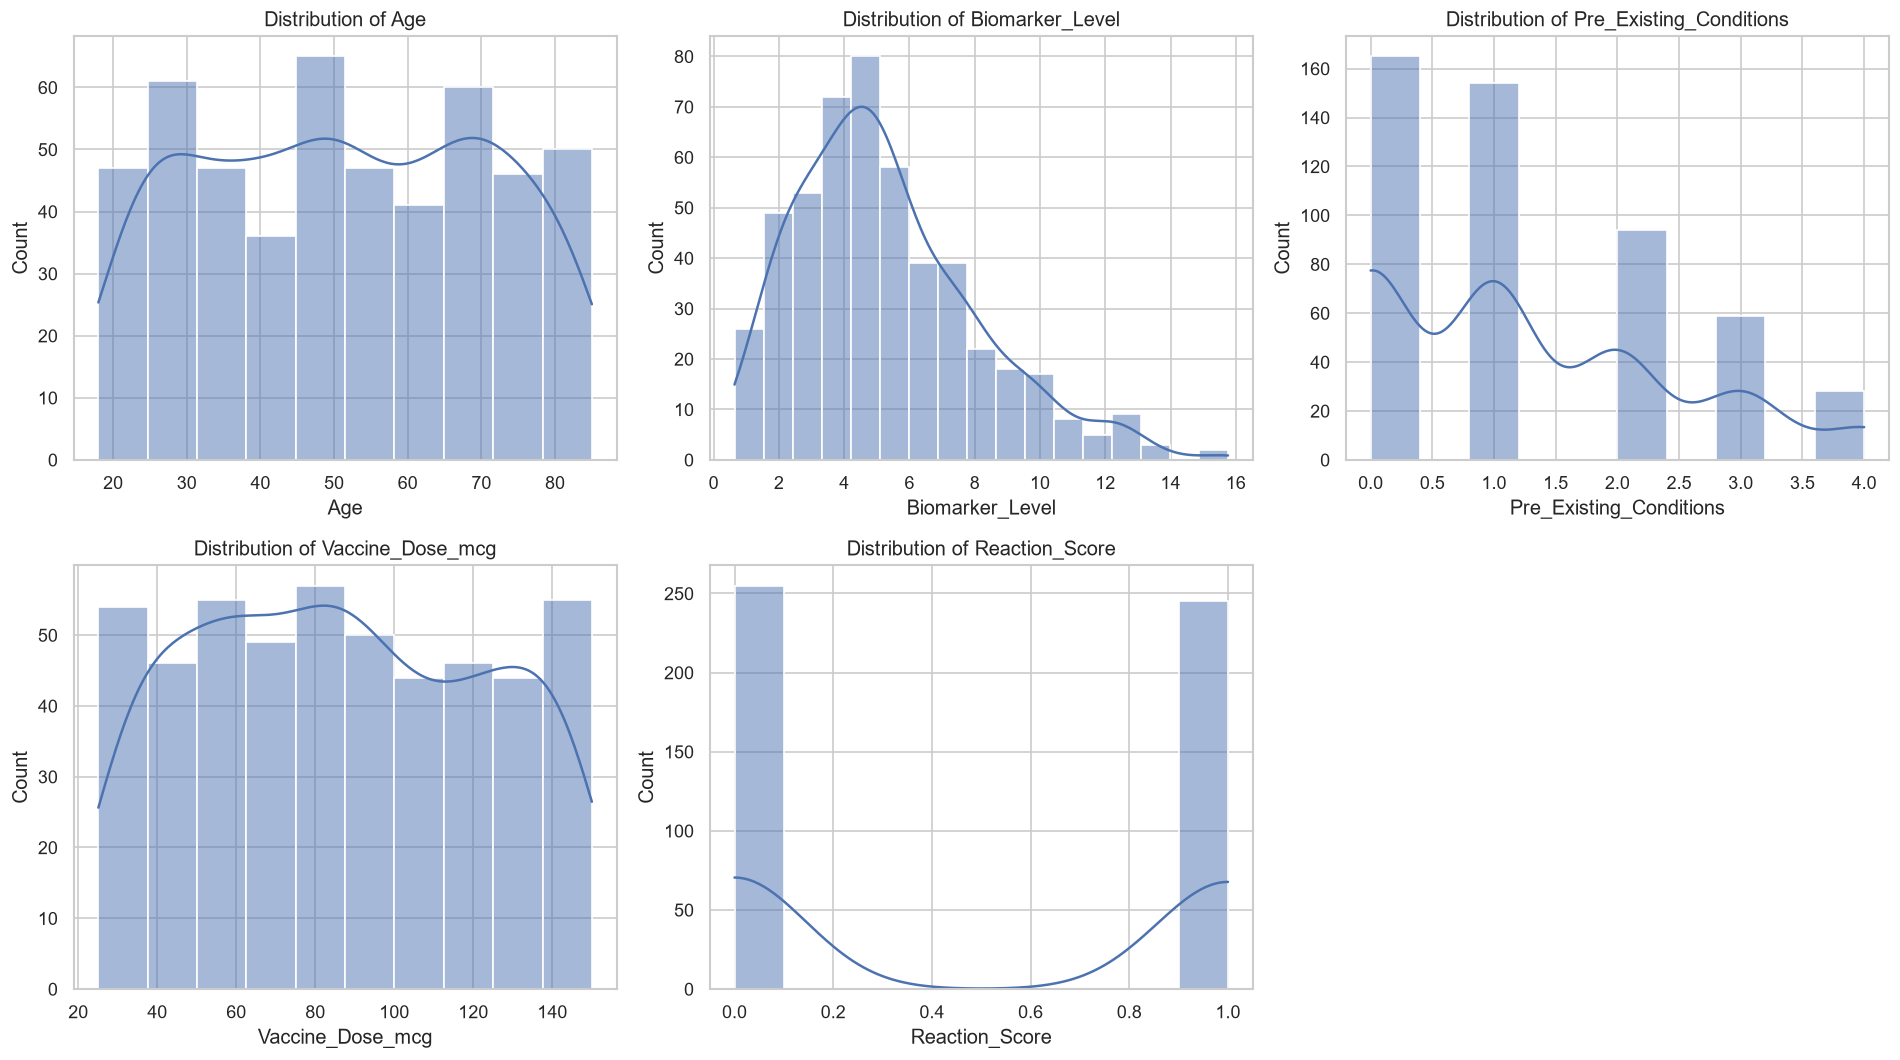

In [21]:
# Numerical feature distributions

numerical_columns = [
    "Age",
    "Biomarker_Level",
    "Pre_Existing_Conditions",
    "Vaccine_Dose_mcg",
    "Reaction_Score"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, column in enumerate(numerical_columns):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {column}")

# Hide unused subplot
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

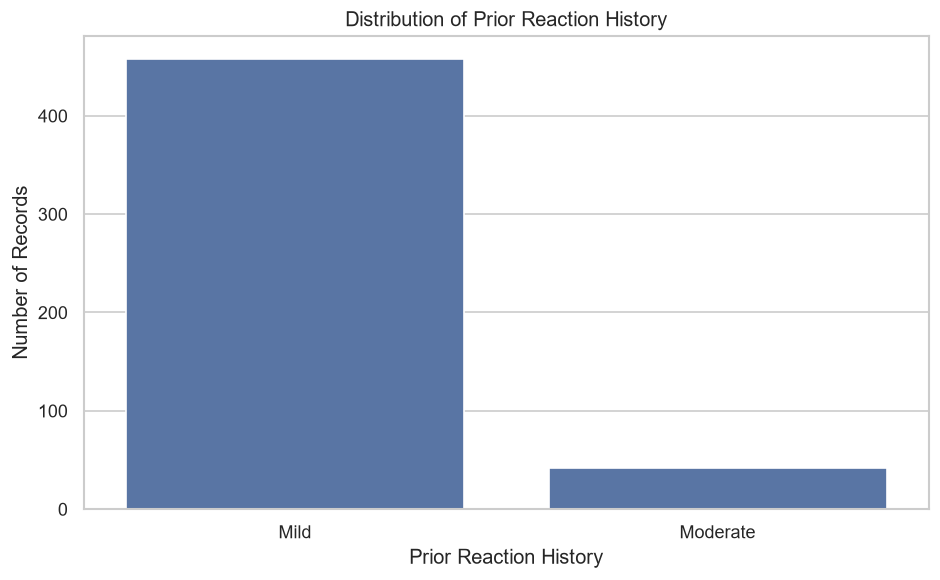

In [22]:
# Distribution of prior reaction history

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Prior_Reaction_History",
    order=df["Prior_Reaction_History"].value_counts().index
)

plt.title("Distribution of Prior Reaction History")
plt.xlabel("Prior Reaction History")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

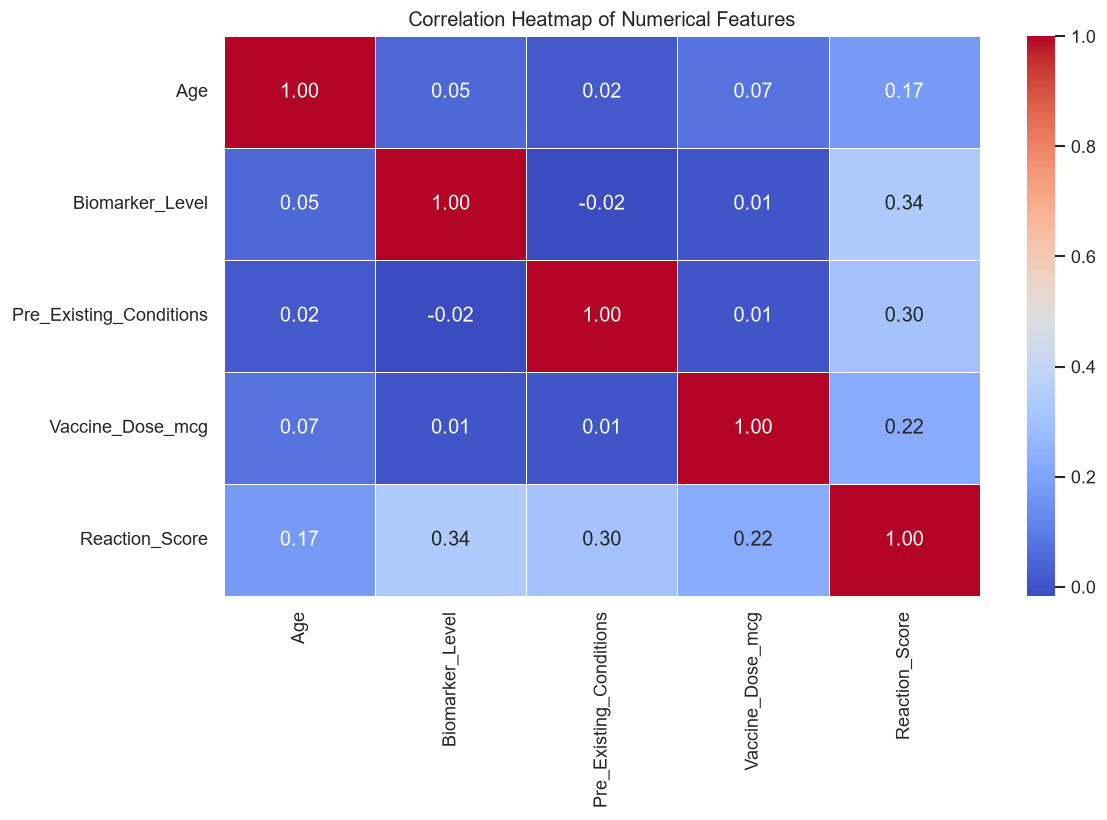

In [23]:
# Correlation analysis of numerical features

correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

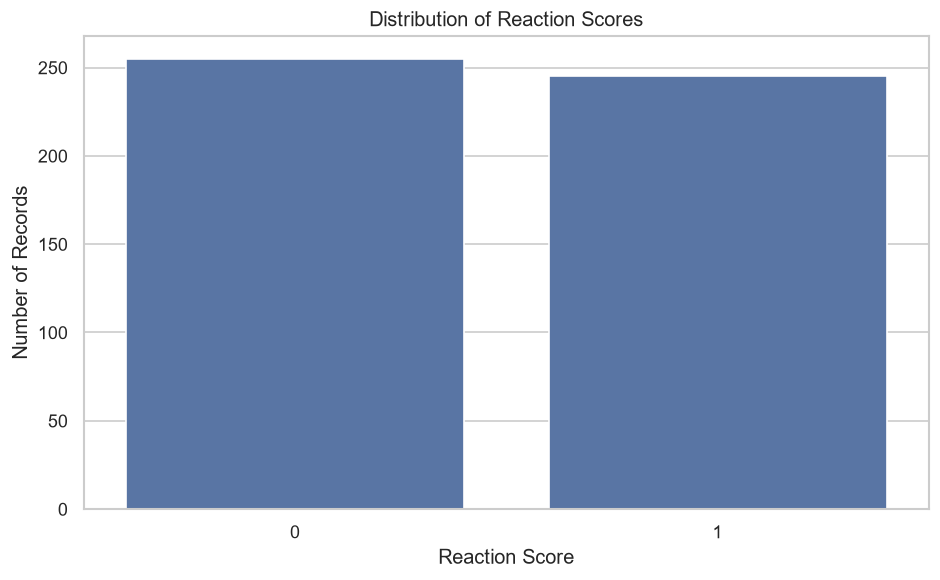

In [24]:
# Reaction score distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Reaction_Score"
)

plt.title("Distribution of Reaction Scores")
plt.xlabel("Reaction Score")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

## Key EDA Findings

### 1. Dataset Quality
- The cleaned dataset contains 500 records and 7 features.
- No missing values were detected.
- No duplicate records were identified.

### 2. Numerical Features
- Age, Biomarker_Level, Pre_Existing_Conditions, Vaccine_Dose_mcg, and Reaction_Score were examined through distribution plots.
- Descriptive statistics were used to understand their central tendency and spread.

### 3. Categorical Features
- Prior_Reaction_History was analyzed using a frequency distribution.
- Mild and Moderate categories are represented in the dataset.

### 4. Correlation Analysis
- A correlation heatmap was generated to explore relationships among numerical features.
- Correlation indicates association, not causation.

### 5. Reaction Score
- Reaction_Score was examined as the target variable.
- Its distribution provides an overview of the two outcome classes.

## Conclusion

The exploratory analysis confirms that the cleaned dataset is structurally complete and suitable for the subsequent educational machine-learning workflow. The visualizations provide an overview of feature distributions, categorical composition, correlations, and reaction-score patterns.

**Disclaimer:** Student engineering project output only. Not real clinical, medical, or regulatory guidance.

In [25]:
# Final EDA validation

print("EDA NOTEBOOK VALIDATION")
print("=" * 40)

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())
print("Numerical visualizations:", len(numerical_columns))
print("Categorical visualizations: 1")
print("Correlation heatmap: Generated")
print("Reaction score visualization: Generated")

assert df.shape == (500, 7)
assert df.isnull().sum().sum() == 0
assert df.duplicated().sum() == 0

print("\nEDA validation completed successfully.")

EDA NOTEBOOK VALIDATION
Dataset shape: (500, 7)
Missing values: 0
Duplicate records: 0
Numerical visualizations: 5
Categorical visualizations: 1
Correlation heatmap: Generated
Reaction score visualization: Generated

EDA validation completed successfully.
